In [28]:
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs, make_moons

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
plt.rcParams["font.family"] = "DejaVu Sans"

np.random.seed(42)

print("Libraries loaded successfully.")

Libraries loaded successfully.


X shape: (200, 2)
Target y: not available


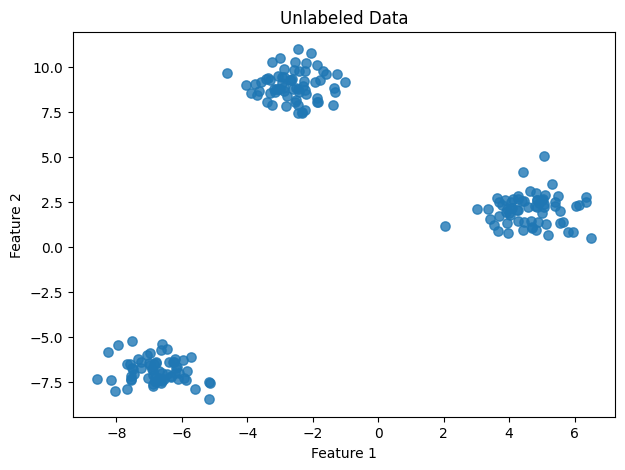

In [23]:
X, _ = make_blobs(
    n_samples=200,
    centers=3,
    cluster_std=0.8,
    random_state=42
)

print("X shape:", X.shape)
print("Target y: not available")

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=45, alpha=0.80)
plt.title("Unlabeled Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [24]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("X_scaled shape:", X_scaled.shape)

print("Mean after scaling:", np.round(X_scaled.mean(axis=0), 3))
print("Std after scaling:", np.round(X_scaled.std(axis=0), 3))

X_scaled shape: (200, 2)
Mean after scaling: [0. 0.]
Std after scaling: [1. 1.]


In [25]:
Kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init="auto",
    random_state=42
)

cluster_labels = Kmeans.fit_predict(X_scaled)
print("Cluster labels:", cluster_labels)

print("\nNUmber of points in each cluster:")
print(pd.Series(cluster_labels).value_counts().sort_index())

Cluster labels: [2 0 1 1 1 1 0 1 2 1 2 2 2 2 2 1 0 1 2 1 2 2 1 0 1 0 0 1 0 2 2 2 1 1 0 0 1
 0 1 0 2 0 1 2 1 2 2 1 2 0 1 0 1 0 0 0 1 2 0 2 1 0 1 1 1 1 0 0 1 0 0 1 0 2
 0 2 2 0 2 0 0 2 2 1 1 1 1 0 2 1 2 0 0 0 2 1 0 2 2 0 1 1 0 1 0 2 1 2 2 1 2
 2 0 1 0 1 1 0 0 0 1 2 0 1 1 2 0 0 2 0 2 1 0 1 1 2 2 2 0 2 0 0 1 2 2 0 2 1
 1 2 0 1 2 1 2 1 1 0 2 2 0 2 2 1 0 2 2 0 1 2 1 0 2 1 0 2 0 0 0 2 0 2 1 1 1
 0 2 2 2 0 0 2 1 1 0 1 0 0 2 2]

NUmber of points in each cluster:
0    67
1    66
2    67
Name: count, dtype: int64


In [26]:
Kmeans

KMeans(n_clusters=3, random_state=42)

/tmp/ipykernel_3599/954611489.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


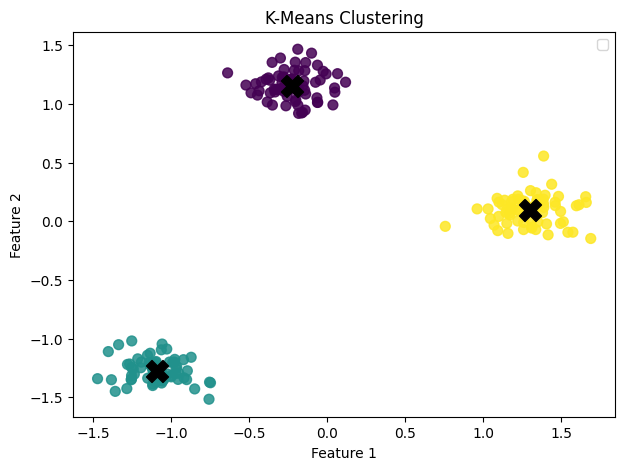

In [27]:
plt.figure(figsize=(7, 5))
plt.scatter(
    X_scaled[:, 0], X_scaled[:, 1],
    c=cluster_labels,
    s=50,
    alpha=0.85
)
plt.scatter(
    Kmeans.cluster_centers_[:,0],
    Kmeans.cluster_centers_[:,1],
    c="black",
    marker="X",
    s=250
)
plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

In [29]:
results=[]
for k in range(2,7):
  model = KMeans(n_clusters=k, n_init="auto",random_state=42)
  label_k = model.fit_predict(X_scaled)

  results.append({
      "k":k,
      "Inertia":model.inertia_,
      "Silhouette": silhouette_score(X_scaled, label_k)
  })

scores = pd.DataFrame(results)
scores


,k,Inertia,Silhouette
0,2,122.945925,0.704145
1,3,7.864161,0.877762
2,4,6.920215,0.696517
3,5,5.980680,0.513161
4,6,4.657182,0.356040


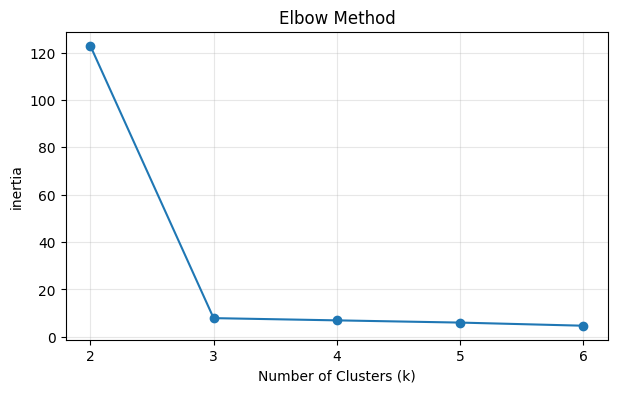

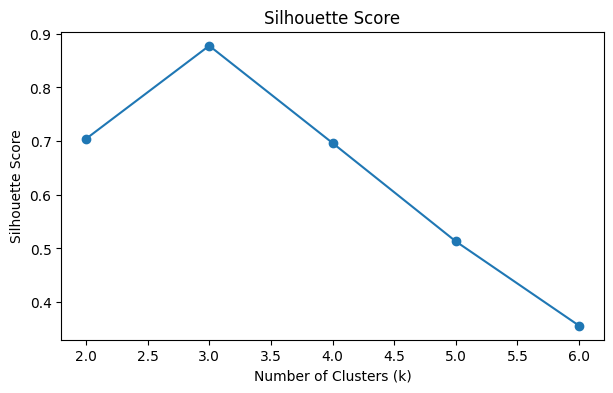

In [32]:
plt.figure(figsize=(7, 4))
plt.plot(scores["k"], scores["Inertia"], marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("inertia")
plt.xticks(scores["k"])
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(scores["k"], scores["Silhouette"], marker="o")
plt.title("Silhouette Score")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.show()

In [34]:
labeled_data = pd.DataFrame(X, columns=["feature_1", "feature_2"])
labeled_data["cluster_label"] = cluster_labels

print("Data after K-Means created labels:")
display(labeled_data.head())

print("\nAverage feature values for each cluster:")
display(
    labeled_data
    .groupby("cluster_label")[["feature_1", "feature_2"]]
    .mean()
    .round(2)
)

Data after K-Means created labels:


,feature_1,feature_2,cluster_label
0,6.132498,2.352236,2
1,-4.604994,9.671808,0
2,-6.889425,-7.597913,1
3,-8.038095,-8.006081,1
4,-7.351119,-6.200428,1



Average feature values for each cluster:


,feature_1,feature_2
cluster_label,,
0,-2.63,8.97
1,-6.77,-6.86
2,4.63,2.08


 **DBSCAN**

DBSCAN labels: [0 1]
DBSCAN labels (-1): 0


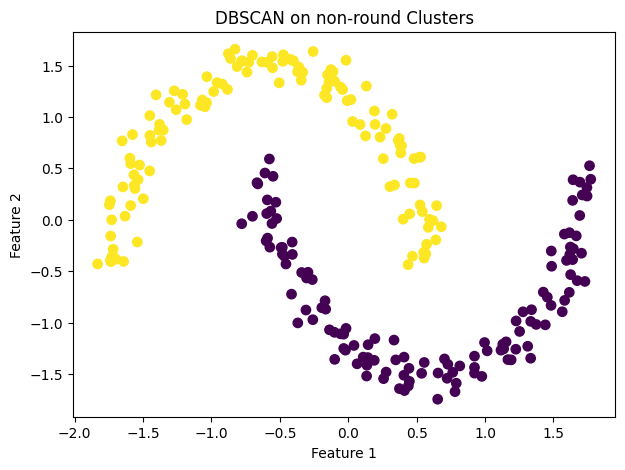

In [37]:
X_moons, _ = make_moons(
    n_samples=250,
    noise=0.06,
    random_state=42
)
X_moons_scaled = StandardScaler().fit_transform(X_moons)

dbscan = DBSCAN(eps=0.3, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_moons_scaled)

print("DBSCAN labels:", np.unique(dbscan_labels))
print("DBSCAN labels (-1):", np.sum(dbscan_labels == -1))

plt.figure(figsize=(7, 5))
plt.scatter(
    X_moons_scaled[:, 0],
    X_moons_scaled[:, 1],
    c=dbscan_labels,
    s=45,
    cmap="viridis"
)
plt.title("DBSCAN on non-round Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**GMM**

In [41]:
gmm = GaussianMixture(n_components=3, random_state=42)
gmm_labels = gmm.fit_predict(X_scaled)
gmm_prop = gmm.predict_proba(X_scaled)

print("Hard GMM labels for first 5 rows:")
print(gmm_labels[:5])

print("\nCluster probabilities for first 5 rows:")
print(gmm_prop[:5])

Hard GMM labels for first 5 rows:
[2 0 1 1 1]

Cluster probabilities for first 5 rows:
[[5.15894355e-047 2.13851930e-134 1.00000000e+000]
 [1.00000000e+000 8.31635851e-146 2.32333046e-046]
 [9.02501995e-103 1.00000000e+000 7.77716274e-068]
 [3.89797147e-111 1.00000000e+000 4.07340769e-077]
 [2.02591617e-089 1.00000000e+000 1.81888331e-063]]


**PCA**

In [46]:
X_high_dim, _ = make_blobs(
    n_samples=3000,
    n_features=10,
    centers=4,
    cluster_std=2.0,
    random_state=42
)
scaler_hd = StandardScaler()
X_high_dim_scaled = scaler_hd.fit_transform(X_high_dim)

kmeans_hd = KMeans(n_clusters=4, n_init=10, random_state=42)
labels_hd = kmeans_hd.fit_predict(X_high_dim_scaled)

pca = PCA(n_components=0.91)
x_pca = pca.fit_transform(X_high_dim_scaled)

print("Original shape:", X_high_dim_scaled.shape)
print("PCA shape:", x_pca.shape)

Original shape: (3000, 10)
PCA shape: (3000, 4)
